# **Import Library**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
products = "/content/drive/MyDrive/Portofolio/E-Commerce/products.csv"
sessions = "/content/drive/MyDrive/Portofolio/E-Commerce/sessions.csv"
funnel = "/content/drive/MyDrive/Portofolio/E-Commerce/funnel.csv"
product_funnel = "/content/drive/MyDrive/Portofolio/E-Commerce/product_funnel.csv"

In [3]:
df_products = pd.read_csv(products)
df_sessions = pd.read_csv(sessions)
df_funnels = pd.read_csv(funnel)
df_product_funnel = pd.read_csv(product_funnel)

# **`Data Formating and Standardization`**

**Date Formating**

In [4]:
#format order date

df_products["order_date"] = pd.to_datetime(df_products["order_date"])
df_products["order_year"] = df_products["order_date"].dt.year
df_products["order_month"] = df_products["order_date"].dt.month

df_sessions["order_date"] = pd.to_datetime(df_sessions["order_date"])
df_sessions["order_year"] = df_sessions["order_date"].dt.year
df_sessions["order_month"] = df_sessions["order_date"].dt.month

df_funnels["order_date"] = pd.to_datetime(df_funnels["order_date"])
df_funnels["order_year"] = df_funnels["order_date"].dt.year
df_funnels["order_month"] = df_funnels["order_date"].dt.month

df_product_funnel["order_date"] = pd.to_datetime(df_product_funnel["order_date"])
df_product_funnel["order_year"] = df_product_funnel["order_date"].dt.year
df_product_funnel["order_month"] = df_product_funnel["order_date"].dt.month

#format session date

df_sessions["session_date"] = pd.to_datetime(df_sessions["session_date"])
df_sessions["session_year"] = df_sessions["session_date"].dt.year
df_sessions["session_month"] = df_sessions["session_date"].dt.month

df_funnels["session_date"] = pd.to_datetime(df_funnels["session_date"])
df_funnels["session_year"] = df_funnels["session_date"].dt.year
df_funnels["session_month"] = df_funnels["session_date"].dt.month

df_product_funnel["session_date"] = pd.to_datetime(df_product_funnel["session_date"])
df_product_funnel["session_year"] = df_product_funnel["session_date"].dt.year
df_product_funnel["session_month"] = df_product_funnel["session_date"].dt.month

#format refund date

df_products["refund_date"] = pd.to_datetime(df_products["refund_date"])
df_products["refund_year"] = df_products["refund_date"].dt.year
df_products["refund_month"] = df_products["refund_date"].dt.month



**Create Fiscal Year Column for Every Table**

In [5]:
df_sessions["financial_year"] = df_sessions['session_date'].dt.year - (df_sessions['session_date'].dt.month < 3)
df_products["financial_year"] = df_products['order_date'].dt.year - (df_products['order_date'].dt.month < 3)
df_funnels["financial_year"] = df_funnels['session_date'].dt.year - (df_funnels['session_date'].dt.month < 3)
df_product_funnel["financial_year"] = df_product_funnel['session_date'].dt.year - (df_product_funnel['session_date'].dt.month < 3)

In [6]:
df_sessions["order_category"] = np.where(df_sessions["items_purchased"]==1, "single-item", "double-item")
df_funnels["order_category"] = np.where(df_funnels["items_purchased"]==1, "single-item", "double-item")

In [7]:
df_sessions['utm_source'] = df_sessions['utm_source'].fillna('n/a')
df_sessions['utm_campaign'] = df_sessions['utm_campaign'].fillna('n/a')
df_sessions['utm_content'] = df_sessions['utm_content'].fillna('n/a')

df_product_funnel['utm_source'] = df_product_funnel['utm_source'].fillna('n/a')
df_product_funnel['utm_campaign'] = df_product_funnel['utm_campaign'].fillna('n/a')
df_product_funnel['utm_content'] = df_product_funnel['utm_content'].fillna('n/a')

df_funnels['utm_source'] = df_funnels['utm_source'].fillna('n/a')
df_funnels['utm_campaign'] = df_funnels['utm_campaign'].fillna('n/a')
df_funnels['utm_content'] = df_funnels['utm_content'].fillna('n/a')

In [8]:
df_products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40025 entries, 0 to 40024
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   id                  40025 non-null  int64         
 1   order_date          40025 non-null  datetime64[ns]
 2   order_id            40025 non-null  int64         
 3   is_primary_item     40025 non-null  int64         
 4   product_name        40025 non-null  object        
 5   price_usd           40025 non-null  float64       
 6   cogs_usd            40025 non-null  float64       
 7   refund_id           1731 non-null   float64       
 8   refund_date         1731 non-null   datetime64[ns]
 9   refund_amount       1731 non-null   float64       
 10  user_id             40025 non-null  int64         
 11  website_session_id  40025 non-null  int64         
 12  order_year          40025 non-null  int32         
 13  order_month         40025 non-null  int32     

In [9]:
df_sessions.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 472871 entries, 0 to 472870
Data columns (total 25 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   id                  472871 non-null  int64         
 1   session_date        472871 non-null  datetime64[ns]
 2   user_id             472871 non-null  int64         
 3   is_repeat_sessions  472871 non-null  int64         
 4   utm_source          472871 non-null  object        
 5   utm_campaign        472871 non-null  object        
 6   utm_content         472871 non-null  object        
 7   device_type         472871 non-null  object        
 8   http_referer        432954 non-null  object        
 9   traffic             472871 non-null  object        
 10  order_id            32313 non-null   float64       
 11  order_date          32313 non-null   datetime64[ns]
 12  items_purchased     32313 non-null   float64       
 13  revenue             32313 non

In [10]:
df_funnels.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1188124 entries, 0 to 1188123
Data columns (total 31 columns):
 #   Column                Non-Null Count    Dtype         
---  ------                --------------    -----         
 0   website_pageviews_id  1188124 non-null  int64         
 1   session_date          1188124 non-null  datetime64[ns]
 2   pageview_url          1188124 non-null  object        
 3   funnel_step           1188124 non-null  object        
 4   session_id            1188124 non-null  int64         
 5   user_id               1188124 non-null  int64         
 6   is_repeat_sessions    1188124 non-null  int64         
 7   utm_source            1188124 non-null  object        
 8   utm_campaign          1188124 non-null  object        
 9   utm_content           1188124 non-null  object        
 10  device_type           1188124 non-null  object        
 11  http_referer          1083790 non-null  object        
 12  traffic               1188124 non-null  ob

In [11]:
df_product_funnel.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 210214 entries, 0 to 210213
Data columns (total 28 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   website_session_id  210214 non-null  int64         
 1   session_date        210214 non-null  datetime64[ns]
 2   is_repeat_sessions  210214 non-null  int64         
 3   utm_source          210214 non-null  object        
 4   utm_campaign        210214 non-null  object        
 5   utm_content         210214 non-null  object        
 6   device_type         210214 non-null  object        
 7   http_referer        191231 non-null  object        
 8   product_id          210214 non-null  int64         
 9   product_name        210214 non-null  object        
 10  item_viewed         210214 non-null  int64         
 11  cart_reached        210214 non-null  int64         
 12  shipping_reached    210214 non-null  int64         
 13  billing_reached     210214 no

**Extract Sessions Data Frame that Contain Orders Data**

In [12]:
# filter for data with orders
order_data = df_sessions["order_id"].notna()
df_orders = df_sessions[order_data]

df_orders_info = df_orders.info()
df_orders_head = df_orders.head()
df_orders_tail = df_orders.tail()

print(df_orders_info)
print(df_orders_head)
print(df_orders_tail)

<class 'pandas.core.frame.DataFrame'>
Index: 32313 entries, 0 to 472866
Data columns (total 25 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   id                  32313 non-null  int64         
 1   session_date        32313 non-null  datetime64[ns]
 2   user_id             32313 non-null  int64         
 3   is_repeat_sessions  32313 non-null  int64         
 4   utm_source          32313 non-null  object        
 5   utm_campaign        32313 non-null  object        
 6   utm_content         32313 non-null  object        
 7   device_type         32313 non-null  object        
 8   http_referer        29457 non-null  object        
 9   traffic             32313 non-null  object        
 10  order_id            32313 non-null  float64       
 11  order_date          32313 non-null  datetime64[ns]
 12  items_purchased     32313 non-null  float64       
 13  revenue             32313 non-null  float64       

**Filtering Net Metrics in Orders Data**

In [13]:
net_order = df_orders['revenue']!= df_orders['refund_amount']
df_net_order = df_orders[net_order]

df_net_order.info()

<class 'pandas.core.frame.DataFrame'>
Index: 31145 entries, 0 to 472866
Data columns (total 25 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   id                  31145 non-null  int64         
 1   session_date        31145 non-null  datetime64[ns]
 2   user_id             31145 non-null  int64         
 3   is_repeat_sessions  31145 non-null  int64         
 4   utm_source          31145 non-null  object        
 5   utm_campaign        31145 non-null  object        
 6   utm_content         31145 non-null  object        
 7   device_type         31145 non-null  object        
 8   http_referer        28385 non-null  object        
 9   traffic             31145 non-null  object        
 10  order_id            31145 non-null  float64       
 11  order_date          31145 non-null  datetime64[ns]
 12  items_purchased     31145 non-null  float64       
 13  revenue             31145 non-null  float64       

In [14]:
df_orders_metric_desc = df_orders[["revenue","net_revenue","profit","refund_amount"]].describe()

df_orders_metric_desc

,revenue,net_revenue,profit,refund_amount
count,32313.000000,32313.000000,32313.000000,1723.000000
mean,59.991636,57.350635,35.984898,49.529129
std,17.808771,20.613766,13.376383,5.870394
min,29.990000,0.000000,0.000000,29.990000
25%,49.990000,49.990000,30.500000,49.990000
50%,49.990000,49.990000,30.500000,49.990000
75%,59.990000,59.990000,37.500000,49.990000
max,109.980000,109.980000,69.000000,109.980000


In [15]:
q1 = df_orders["revenue"].quantile(0.25)
q3 = df_orders["revenue"].quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

lower_outliers = df_orders["revenue"] < lower_bound
upper_outliers = df_orders["revenue"] > upper_bound

print(lower_bound)
print(upper_bound)
print(lower_outliers.sum())
print(upper_outliers.sum())

34.99
74.99000000000001
534
7712


In [16]:
revenue_frequency = df_orders["revenue"].value_counts().sort_values()
revenue_frequency_percentage = round(df_orders["revenue"].value_counts(normalize=True)*100,2)

print("revenue_frequency:")
print(revenue_frequency)
print("revenue_frequency_percentage:")
print(revenue_frequency_percentage)

revenue_frequency:
revenue
105.98      248
29.99       534
75.98       662
89.98       680
109.98      944
95.98      2036
45.99      2039
79.98      3142
59.99      3924
49.99     18104
Name: count, dtype: int64
revenue_frequency_percentage:
revenue
49.99     56.03
59.99     12.14
79.98      9.72
45.99      6.31
95.98      6.30
109.98     2.92
89.98      2.10
75.98      2.05
29.99      1.65
105.98     0.77
Name: proportion, dtype: float64


In [17]:
df_products["order_revenue"] = df_products[(df_products['order_date'] >= '2014-09-19')&(df_products['order_date'] <= '2015-03-19')].groupby("order_id")["price_usd"].transform("sum")

revenue_list = df_products[["order_revenue","product_name"]].value_counts(normalize=True)*100

print("product_combination:")
revenue_list

product_combination:


order_revenue  product_name              
49.99          The Original Mr. Fuzzy        29.826098
79.98          The Original Mr. Fuzzy        10.815714
               The Hudson River Mini bear    10.815714
59.99          The Forever Love Bear          9.095459
95.98          The Birthday Sugar Panda       6.668335
               The Original Mr. Fuzzy         6.668335
45.99          The Birthday Sugar Panda       6.149130
29.99          The Hudson River Mini bear     3.321656
109.98         The Forever Love Bear          2.671087
               The Original Mr. Fuzzy         2.671087
89.98          The Forever Love Bear          2.452146
               The Hudson River Mini bear     2.452146
75.98          The Birthday Sugar Panda       2.439635
               The Hudson River Mini bear     2.439635
105.98         The Forever Love Bear          0.756912
               The Birthday Sugar Panda       0.756912
Name: proportion, dtype: float64

In [18]:
df_products["total_revenue"] = df_products.groupby("order_id")["price_usd"].transform("sum")
df_products["total_item"] = df_products.groupby("order_id")["product_name"].transform("count")

high_orders = df_products[df_products["total_revenue"] > upper_bound]
low_orders = df_products[df_products["total_revenue"] < lower_bound]

product_details = high_orders[["product_name","price_usd","order_id","total_revenue","total_item"]]
item_check = product_details[product_details["total_item"] < 2]

print(item_check)


Empty DataFrame
Columns: [product_name, price_usd, order_id, total_revenue, total_item]
Index: []


**KPI Metrics**

In [19]:
# KPI metrics
total_traffic = df_sessions["id"].count()
overal_conversion = round(df_orders["order_id"].count()/total_traffic*100,2)
total_gross_revenue = round(df_orders["revenue"].sum(),2)
total_refund_amount = round(df_orders["refund_amount"].sum(),2)
total_net_revenue = round(df_net_order['net_revenue'].sum(),2)
total_profit = round(df_orders["profit"].sum(),2)
total_orders = df_orders["order_id"].count()
total_net_order = df_net_order["order_id"].count()
refund_rate = round(total_refund_amount/total_gross_revenue*100,2)
gross_aov = round(total_gross_revenue/total_orders,2)
aov = round(total_net_revenue/total_net_order,2)

print(f"Total Traffic: {total_traffic}")
print(f"Overall Conversion Rate: {overal_conversion}%")
print(f"Total Gross Revenue: {total_gross_revenue}")
print(f"Total Refund Amount: {total_refund_amount}")
print(f"Total Net Revenue: {total_net_revenue}")
print(f"Total Profit: {total_profit}")
print(f"Total Orders: {total_orders}")
print(f"Total Net Orders: {total_net_order}")
print(f"Refund Rate: {refund_rate}%")
print(f"Gross AOV: {gross_aov}")
print(f"AOV: {aov}")

Total Traffic: 472871
Overall Conversion Rate: 6.83%
Total Gross Revenue: 1938509.75
Total Refund Amount: 85338.69
Total Net Revenue: 1853171.06
Total Profit: 1162780.0
Total Orders: 32313
Total Net Orders: 31145
Refund Rate: 4.4%
Gross AOV: 59.99
AOV: 59.5


**Metric by Financial Year**

In [20]:
net_metric_by_financial_year = (
    df_net_order.groupby("financial_year")
    .agg(
        total_net_revenue=("net_revenue","sum"),
        total_net_order=("order_id","count")
    )
)
net_metric_by_financial_year["aov"] = round(net_metric_by_financial_year["total_net_revenue"]/net_metric_by_financial_year["total_net_order"],2)
net_metric_by_financial_year["net_revenue_growth"] = round(net_metric_by_financial_year["total_net_revenue"].pct_change()*100,2)
net_metric_by_financial_year["net_order_growth"] = round(net_metric_by_financial_year["total_net_order"].pct_change()*100,2)
net_metric_by_financial_year["aov_growth"] = round(net_metric_by_financial_year["aov"].pct_change()*100,2)

net_metric_by_financial_year


,total_net_revenue,total_net_order,aov,net_revenue_growth,net_order_growth,aov_growth
financial_year,,,,,,
2012,164627.48,3252,50.62,NaN,NaN,NaN
2013,450009.99,8221,54.74,173.35,152.80,8.14
2014,1162275.97,18445,63.01,158.28,124.36,15.11
2015,76257.62,1227,62.15,-93.44,-93.35,-1.36


In [21]:
gross_metric_by_financial_year =(
    df_orders.groupby("financial_year")
    .agg(
        total_gross_revenue=("revenue","sum"),
        total_orders=("order_id","count"),
        total_refund_amount=("refund_amount","sum")
    )
)
gross_metric_by_financial_year["aov"] = round(gross_metric_by_financial_year["total_gross_revenue"]/gross_metric_by_financial_year["total_orders"],2)
gross_metric_by_financial_year["refund_rate"] = round(gross_metric_by_financial_year["total_refund_amount"]/gross_metric_by_financial_year["total_gross_revenue"]*100,2)
gross_metric_by_financial_year["gross_revenue_growth"] = round(gross_metric_by_financial_year["total_gross_revenue"].pct_change()*100,2)
gross_metric_by_financial_year["order_growth"] = round(gross_metric_by_financial_year["total_orders"].pct_change()*100,2)
gross_metric_by_financial_year["aov_growth"] = round(gross_metric_by_financial_year["aov"].pct_change()*100,2)

gross_metric_by_financial_year

,total_gross_revenue,total_orders,total_refund_amount,aov,refund_rate,gross_revenue_growth,order_growth,aov_growth
financial_year,,,,,,,,
2012,175755.26,3474,11127.78,50.59,6.33,NaN,NaN,NaN
2013,469428.14,8563,19418.15,54.82,4.14,167.09,146.49,8.36
2014,1214375.28,19022,52099.31,63.84,4.29,158.69,122.14,16.45
2015,78951.07,1254,2693.45,62.96,3.41,-93.50,-93.41,-1.38


**Basket Order by Financial Year**

In [22]:
order_item_by_financial_year = df_orders.pivot_table(
    index="financial_year",
    columns="order_category",
    values="items_purchased",
    aggfunc="count"
)

order_item_by_financial_year

order_category,double-item,single-item
financial_year,,
2012,NaN,3474.0
2013,623.0,7940.0
2014,6650.0,12372.0
2015,439.0,815.0


In [23]:
order_metric_by_financial_year =(
    df_sessions.groupby("financial_year")
    .agg(
        total_traffic=("id","count"),
        total_orders=("order_id","count")
    )
)
order_metric_by_financial_year["conversion_rate"] = round(order_metric_by_financial_year["total_orders"]/order_metric_by_financial_year["total_traffic"]*100,2)
order_metric_by_financial_year["traffic_growth"] = round(order_metric_by_financial_year["total_traffic"].pct_change()*100,2)
order_metric_by_financial_year["conversion_growth"] = round(order_metric_by_financial_year["conversion_rate"].pct_change()*100,2)

order_metric_by_financial_year

,total_traffic,total_orders,conversion_rate,traffic_growth,conversion_growth
financial_year,,,,,
2012,76039,3474,4.57,NaN,NaN
2013,130322,8563,6.57,71.39,43.76
2014,251427,19022,7.57,92.93,15.22
2015,15083,1254,8.31,-94.00,9.78


**Monthly Trend**

In [24]:
trend_total_traffic = df_sessions.pivot_table(
    index=["session_year","session_month"],
    values="id",
    aggfunc="count"
)

trend_net_revenue = df_orders.pivot_table(
    index=["order_year","order_month"],
    values="net_revenue",
    aggfunc="sum"
)

trend_gross_revenue = df_orders.pivot_table(
    index=["order_year","order_month"],
    values="revenue",
    aggfunc="sum"
).reset_index()

trend_order = df_orders.pivot_table(
    index=["order_year","order_month"],
    values="order_id",
    aggfunc="count"
).reset_index()

trend_refund = df_orders[df_orders["refund_amount"].notna()].pivot_table(
    index=["order_year","order_month"],
    values="refund_amount",
    aggfunc="sum"
).reset_index()

trend_metrics = trend_gross_revenue.merge(trend_order, on=["order_year","order_month"], how="left")
trend_metrics = trend_metrics.merge(trend_refund, on=["order_year","order_month"], how="left")
trend_metrics["aov"] = round(trend_metrics["revenue"]/trend_metrics["order_id"],2)

trend_metrics_pivot = trend_metrics.pivot_table(
    index=["order_year","order_month"],
    values=["revenue","aov","order_id","refund_amount"],
    aggfunc="sum"
)


In [25]:
trend_total_traffic

id
session_year session_month       
2012         3               1879
             4               3734
             5               3736
             6               3963
             7               4249
             8               6097
             9               6546
             10              8183
             11             14011
             12             10072
2013         1               6401
             2               7168
             3               6264
             4               7971
             5               8449
             6               8325
             7               8903
             8               9180
             9               9580
             10             10773
             11             14032
             12             15735
2014         1              14825
             2              16285
             3              15669
             4              17353
             5              18061
             6              17715
             7              19038
             8              18590
             9              19513
             10             21526
             11             25125
             12             29722
2015         1              25337
             2              23778
             3              15083

In [26]:
trend_metrics_pivot

aov  order_id  refund_amount    revenue
order_year order_month                                           
2012.0     3.0          49.99        60          49.99    2999.40
           4.0          49.99        99         249.95    4949.01
           5.0          49.99       108         199.96    5398.92
           6.0          49.99       140         399.92    6998.60
           7.0          49.99       169         699.86    8448.31
           8.0          49.99       228         849.83   11397.72
           9.0          49.99       287        1299.74   14347.13
           10.0         49.99       371        1349.73   18546.29
           11.0         49.99       618        2299.54   30893.82
           12.0         49.99       506        1499.70   25294.94
2013.0     1.0          51.20       390         909.82   19966.10
           2.0          53.24       498        1319.74   26515.02
           3.0          51.68       385        1079.79   19896.15
           4.0          51.69       553        1009.80   28584.47
           5.0          51.43       571        1669.67   29364.29
           6.0          51.51       593        2249.56   30544.07
           7.0          51.56       604        2029.60   31143.96
           8.0          51.60       608        1459.71   31373.92
           9.0          52.02       629        1209.76   32723.65
           10.0         54.02       708         969.81   38242.62
           11.0         54.16       861        1489.71   46631.02
           12.0         55.65      1047        1649.67   58262.60
2014.0     1.0          57.61       982        2387.52   56568.89
           2.0          64.65      1021        2213.55   66012.52
           3.0          63.97      1066        2191.55   68189.73
           4.0          63.44      1241        2787.42   78725.43
           5.0          65.01      1368        2581.47   88935.27
           6.0          64.61      1239        4005.18   80051.25
           7.0          64.77      1286        3265.34   83288.55
           8.0          63.94      1325        7818.42   84716.08
           9.0          64.77      1424        8564.27   92232.49
           10.0         64.58      1609        2771.41  103905.98
           11.0         64.57      1985        4217.13  128162.98
           12.0         62.59      2314        5338.89  144823.02
2015.0     1.0          63.02      2098        4789.01  132211.54
           2.0          62.48      2068        3769.22  129212.94
           3.0          62.96      1254        2693.45   78951.07

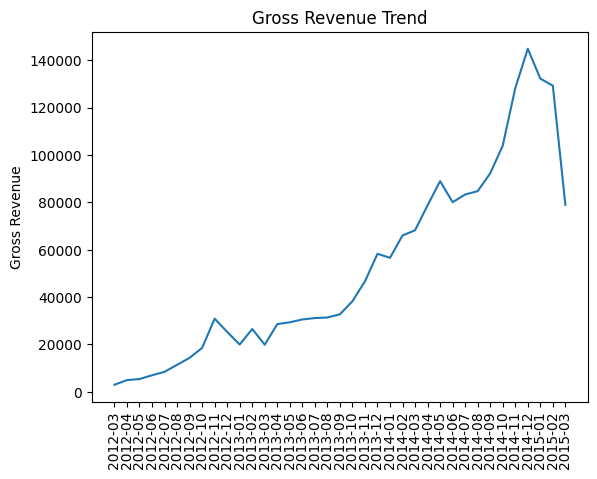

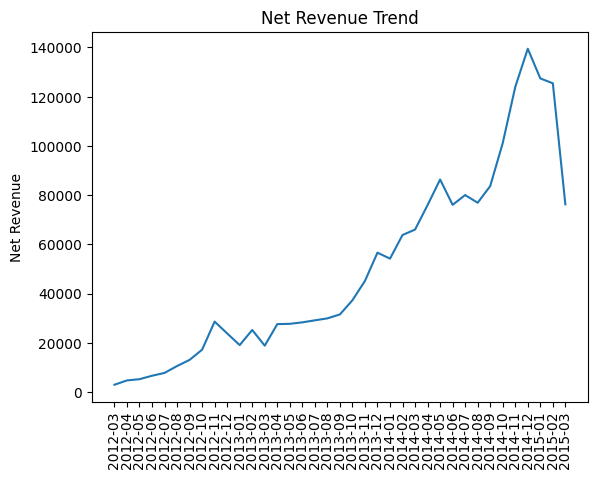

In [27]:
# Create a more plottable index from the MultiIndex
plot_index_traffic = trend_total_traffic.index.map(lambda x: f"{int(x[0])}-{int(x[1]):02d}")
plot_index = trend_metrics_pivot.index.map(lambda x: f"{int(x[0])}-{int(x[1]):02d}")

plt.plot(
    plot_index,
    trend_metrics_pivot["revenue"],
    label="Revenue"
)
plt.title("Gross Revenue Trend")
plt.ylabel("Gross Revenue")
plt.xticks(rotation=90)
plt.show()

plt.plot(
    plot_index,
    trend_net_revenue["net_revenue"],
    label="Net Revenue"
)
plt.title("Net Revenue Trend")
plt.ylabel("Net Revenue")
plt.xticks(rotation=90)
plt.show()

# **Product Analysis**

**Product Metrics**

In [28]:
# create product profit column
df_products["profit"] = df_products["price_usd"]-df_products["cogs_usd"]

# product net metrics summary
product_summary_net = (
    df_products[df_products["refund_id"].isna()]
    .groupby("product_name")
    .agg(
        total_net_revenue = ("price_usd","sum"),
        total_net_orders=("id","count"),
        total_profit = ("profit","sum"),
        aov = ("price_usd","mean")
    )
    .sort_values("total_net_revenue", ascending=False)
).reset_index()

# product net revenue contribution
product_total_net_revenue = (
    product_summary_net["total_net_revenue"]
    .sum()
)
product_summary_net["revenue_contribution"] = round(
    product_summary_net["total_net_revenue"]/product_total_net_revenue*100, 2
)

# product refund amount
product_refund = (
    df_products.groupby("product_name")
    .agg(
        refund_amount = ("refund_amount","sum"),
        gross_revenue=("price_usd","sum")
    )
).reset_index()

# product refund amount contribution
product_total_refund_amount = (
    product_refund["refund_amount"]
    .sum()
)

product_refund["refund_contribution"] = round(
    product_refund["refund_amount"]/product_total_refund_amount*100, 2
)

product_summary_net = product_summary_net.merge(product_refund, on="product_name", how="left")
product_summary_net["refund_rate"] = round(
    product_summary_net["refund_amount"]/product_summary_net["gross_revenue"]*100, 2
)

product_exist_date = (
    df_products.groupby("product_name")
    .agg(
        first_date=("order_date","min"),
        last_date=("order_date","max")
    )
    .reset_index()
)
product_exist_date['days_count'] = (product_exist_date['last_date'] - product_exist_date['first_date']).dt.days

product_summary_net = product_summary_net.merge(product_exist_date, on="product_name", how="left")
product_summary_net['revenue_per_day'] = round(product_summary_net['total_net_revenue']/product_summary_net['days_count'],2)
product_summary_net['order_per_day'] = round(product_summary_net['total_net_orders']/product_summary_net['days_count'],2)

print("Product Summary:")
product_summary_net

Product Summary:


,product_name,total_net_revenue,total_net_orders,total_profit,aov,revenue_contribution,refund_amount,gross_revenue,refund_contribution,refund_rate,first_date,last_date,days_count,revenue_per_day,order_per_day
0,The Original Mr. Fuzzy,1149220.11,22989,701164.5,49.99,62.01,61837.63,1211057.74,72.46,5.11,2012-03-19 10:42:46,2015-03-19 05:38:31,1094,1050.48,21.01
1,The Forever Love Bear,339963.33,5667,212512.5,59.99,18.34,7738.71,347702.04,9.07,2.23,2013-01-07 11:40:06,2015-03-19 05:27:28,800,424.95,7.08
2,The Birthday Sugar Panda,215417.16,4684,147546.0,45.99,11.62,13842.99,229260.15,16.22,6.04,2013-12-12 11:49:54,2015-03-19 01:51:39,461,467.28,10.16
3,The Hudson River Mini bear,148570.46,4954,101557.0,29.99,8.02,1919.36,150489.82,2.25,1.28,2014-02-05 11:02:39,2015-03-19 05:35:57,406,365.94,12.20


**Product First 6 Month baseline**

In [29]:
product_date_first_six_month = df_products.groupby("product_name")['order_date'].min().reset_index(name='first_date')
# Calculate '6th_month' while 'first_date' is still datetime64[ns]
product_date_first_six_month['6th_month'] = product_date_first_six_month['first_date'] + pd.DateOffset(months=6)

# Now convert both 'first_date' and '6th_month' to date objects
product_date_first_six_month['first_date'] = product_date_first_six_month['first_date'].dt.date
product_date_first_six_month['6th_month'] = product_date_first_six_month['6th_month'].dt.date

product_date_first_six_month

,product_name,first_date,6th_month
0,The Birthday Sugar Panda,2013-12-12,2014-06-12
1,The Forever Love Bear,2013-01-07,2013-07-07
2,The Hudson River Mini bear,2014-02-05,2014-08-05
3,The Original Mr. Fuzzy,2012-03-19,2012-09-19


**Product Metrics for First 6 Months**

In [30]:
# product gross metrics of first 6 months
product_gross_data = df_products.merge(product_date_first_six_month, how='left', on='product_name')
product_gross_data_first_six_month = product_gross_data[product_gross_data['order_date'] <= product_gross_data['6th_month']]
product_gross_metrics_first_six_month = (
    product_gross_data_first_six_month.groupby('product_name')
    .agg(
        gross_revenue=('price_usd', 'sum'),
        total_orders=('order_id', 'count'),
        price=('price_usd', 'mean'),
        refund_amount=('refund_amount', 'sum')
    )
)
product_gross_metrics_first_six_month['refund_rate'] = round(product_gross_metrics_first_six_month['refund_amount'] / product_gross_metrics_first_six_month['gross_revenue'] * 100, 2)

# product net metrics of first 6 months
product_net_data = df_products[df_products['refund_id'].isna()].merge(product_date_first_six_month, how='left', on='product_name')
product_net_data_first_six_month = product_net_data[product_net_data['order_date'] <= product_net_data['6th_month']]
product_net_metrics_first_six_month = (
    product_net_data_first_six_month.groupby('product_name')
    .agg(
        net_revenue=('price_usd', 'sum'),
        total_orders=('order_id', 'count'),
        price=('price_usd', 'mean'),
        profit=('profit', 'sum')
    )
)
product_net_metrics_first_six_month['margin'] = round(product_net_metrics_first_six_month['profit'] / product_net_metrics_first_six_month['net_revenue'] * 100, 2)

# product summary metrics of first 6 months
product_summary_metrics_first_six_month = product_gross_metrics_first_six_month[['gross_revenue','refund_rate']].merge(product_net_metrics_first_six_month, on='product_name', how='left')
product_summary_metrics_first_six_month = product_summary_metrics_first_six_month[['gross_revenue','net_revenue','total_orders','price','margin','refund_rate']].sort_values('net_revenue', ascending=False)

print("First 6 Months Performance of Each Product: ")
product_summary_metrics_first_six_month.reset_index()

First 6 Months Performance of Each Product: 


,product_name,gross_revenue,net_revenue,total_orders,price,margin,refund_rate
0,The Birthday Sugar Panda,67973.22,63604.17,1383,45.99,68.49,6.43
1,The Original Mr. Fuzzy,48040.39,44841.03,897,49.99,61.01,6.66
2,The Hudson River Mini bear,45344.88,44775.07,1493,29.99,68.36,1.26
3,The Forever Love Bear,33354.44,32514.58,542,59.99,62.51,2.52


**Product Last 6 Month baseline**

In [31]:
product_date_last_six_month = df_products.groupby("product_name")['order_date'].max().reset_index(name='last_date')
product_date_last_six_month['1st_month'] = product_date_last_six_month['last_date'] - pd.DateOffset(months=6)

product_date_last_six_month['last_date'] = product_date_last_six_month['last_date'].dt.date
product_date_last_six_month['1st_month'] = product_date_last_six_month['1st_month'].dt.date

product_date_last_six_month

,product_name,last_date,1st_month
0,The Birthday Sugar Panda,2015-03-19,2014-09-19
1,The Forever Love Bear,2015-03-19,2014-09-19
2,The Hudson River Mini bear,2015-03-19,2014-09-19
3,The Original Mr. Fuzzy,2015-03-19,2014-09-19


**Product Metrics for Last 6 Months**

In [32]:
# product gross metrics of last 6 months
product_gross_data_last = df_products.merge(product_date_last_six_month, how='left', on='product_name')
product_gross_data_last_six_month = product_gross_data_last[product_gross_data_last['order_date'] >= product_gross_data_last['1st_month']]
product_gross_metrics_last_six_month = (
    product_gross_data_last_six_month.groupby('product_name')
    .agg(
        gross_revenue=('price_usd', 'sum'),
        total_orders=('id', 'count'),
        price=('price_usd', 'mean'),
        refund_amount=('refund_amount', 'sum')
    )
)
product_gross_metrics_last_six_month['refund_rate'] = round(product_gross_metrics_last_six_month['refund_amount'] / product_gross_metrics_last_six_month['gross_revenue'] * 100, 2)

# product net metrics of last 6 months
product_net_data_last = df_products[df_products['refund_id'].isna()].merge(product_date_last_six_month, how='left', on='product_name')
product_net_data_last_six_month = product_net_data_last[product_net_data_last['order_date'] >= product_net_data_last['1st_month']]
product_net_metrics_last_six_month = (
    product_net_data_last_six_month.groupby('product_name')
    .agg(
        net_revenue=('price_usd', 'sum'),
        total_net_orders=('order_id', 'count'),
        aov=('price_usd', 'mean'),
        profit=('profit', 'sum')
    )
)
product_net_metrics_last_six_month['margin'] = round(product_net_metrics_last_six_month['profit'] / product_net_metrics_last_six_month['net_revenue'] * 100, 2)

# product summary metrics of last 6 months
product_summary_metrics_last_six_month = product_gross_metrics_last_six_month[['gross_revenue','refund_rate']].merge(product_net_metrics_last_six_month, on='product_name', how='left')
product_summary_metrics_last_six_month = product_summary_metrics_last_six_month[['gross_revenue','net_revenue','total_net_orders','aov','margin','refund_rate']].sort_values('net_revenue', ascending=False)

print("Last 6 Months Performance of Each Product: ")
product_summary_metrics_last_six_month = product_summary_metrics_last_six_month.reset_index()
product_summary_metrics_last_six_month

Last 6 Months Performance of Each Product: 


,product_name,gross_revenue,net_revenue,total_net_orders,aov,margin,refund_rate
0,The Original Mr. Fuzzy,399670.05,386272.73,7727,49.99,61.01,3.35
1,The Forever Love Bear,143736.04,140556.57,2343,59.99,62.51,2.21
2,The Birthday Sugar Panda,117826.38,110789.91,2409,45.99,68.49,5.97
3,The Hudson River Mini bear,91379.53,90119.95,3005,29.99,68.36,1.38


**Basket Order Metrics**

In [33]:
product_item_purchased = df_net_order.groupby("order_category").agg(
    total_revenue=("net_revenue","sum"),
    total_orders=("order_id","count"),
    total_profit=("profit","sum")
)
product_item_purchased["aov"] = round(product_item_purchased["total_revenue"]/product_item_purchased["total_orders"],2)
product_item_purchased["margin"] = round(product_item_purchased["total_profit"]/product_item_purchased["total_revenue"]*100,2)

product_item_purchased_refund = df_orders.groupby("order_category").agg(
    total_refund_amount=("refund_amount","sum"),
    total_gross_revenue=("revenue","sum")
)
product_item_purchased_refund["refund_rate"] = round(product_item_purchased_refund["total_refund_amount"]/product_item_purchased_refund["total_gross_revenue"]*100,2
)

product_item_purchased = product_item_purchased.merge(product_item_purchased_refund, on="order_category", how="left")

product_item_purchased[["total_revenue","total_orders","aov","total_profit","margin","refund_rate"]]

,total_revenue,total_orders,aov,total_profit,margin,refund_rate
order_category,,,,,,
double-item,661251.47,7704,85.83,424371.5,64.18,3.93
single-item,1191919.59,23441,50.85,738408.5,61.95,4.66


In [34]:
basket_product = (
    df_products[df_products['order_revenue']>60].groupby(["order_revenue","product_name"])
    ["price_usd"]
    .mean()
)

basket_product

order_revenue  product_name              
75.98          The Birthday Sugar Panda      45.99
               The Hudson River Mini bear    29.99
79.98          The Hudson River Mini bear    29.99
               The Original Mr. Fuzzy        49.99
89.98          The Forever Love Bear         59.99
               The Hudson River Mini bear    29.99
95.98          The Birthday Sugar Panda      45.99
               The Original Mr. Fuzzy        49.99
105.98         The Birthday Sugar Panda      45.99
               The Forever Love Bear         59.99
109.98         The Forever Love Bear         59.99
               The Original Mr. Fuzzy        49.99
Name: price_usd, dtype: float64

In [35]:
basket_product_gross_value = (
    df_orders.groupby("revenue")
    .agg(
        total_orders=("order_id","count"),
        total_gross_revenue=("revenue","sum"),
        total_refund_amount=("refund_amount","sum"),
    )
)
basket_product_gross_value["gross_aov"] = round(basket_product_gross_value["total_gross_revenue"]/basket_product_gross_value["total_orders"],2)
basket_product_gross_value["refund_rate"] = round(basket_product_gross_value["total_refund_amount"]/basket_product_gross_value["total_gross_revenue"]*100,2)

basket_product_net_value = (
    df_net_order.groupby("revenue")
    .agg(
        total_net_orders=("order_id","count"),
        total_net_revenue=("net_revenue","sum"),
        total_profit=("profit","sum"),
    )
)
basket_product_net_value["aov"] = round(basket_product_net_value["total_net_revenue"]/basket_product_net_value["total_net_orders"],2)
basket_product_net_value["margin"] = round(basket_product_net_value["total_profit"]/basket_product_net_value["total_net_revenue"]*100,2)

basket_product_value = basket_product_gross_value.merge(basket_product_net_value, on="revenue", how="left")

basket_product_value[["total_net_revenue","total_net_orders","aov","total_profit","margin","refund_rate"]].sort_values("total_net_revenue", ascending=False)

,total_net_revenue,total_net_orders,aov,total_profit,margin,refund_rate
revenue,,,,,,
49.99,858178.33,17167,49.99,523593.5,61.01,5.18
79.98,242589.05,3140,77.26,154847.5,63.83,3.47
59.99,229881.68,3832,59.99,143700.0,62.51,2.34
95.98,185381.38,2032,91.23,119711.0,64.58,5.13
109.98,100041.84,942,106.20,61870.0,61.84,3.64
45.99,88024.86,1914,45.99,60291.0,68.49,6.13
89.98,60076.64,680,88.35,38727.0,64.46,1.81
75.98,47929.31,662,72.40,32801.5,68.44,4.71
105.98,25233.25,248,101.75,16414.5,65.05,3.99


**Product Growth by Year**

In [36]:
# product monthly revenue and monthly growth
product_traffic_monthly = df_product_funnel.pivot_table(
    index="financial_year",
    columns="product_name",
    values="item_viewed",
    aggfunc="sum"
)

product_traffic_monthly_growth = (
    product_traffic_monthly.pct_change()*100
)

print("product_traffic_monthly")
product_traffic_monthly

product_traffic_monthly


product_name,The Birthday Sugar Panda,The Forever Love Bear,The Hudson River Mini bear,The Original Mr. Fuzzy
financial_year,,,,
2012,NaN,1103.0,NaN,25547.0
2013,2220.0,7950.0,NaN,45182.0
2014,15843.0,16090.0,2155.0,86402.0
2015,983.0,890.0,455.0,5394.0


In [74]:
product_conversion_monthly= (
    df_product_funnel.groupby(["financial_year","product_name"])
    .agg(
        total_item_viewed=("item_viewed","sum"),
        total_purchase_completed=("purchase_completed","sum")
    )
)

product_conversion_monthly["conversion_rate"] = round(
    product_conversion_monthly["total_purchase_completed"]/product_conversion_monthly["total_item_viewed"]*100, 2
)

product_conversion_monthly_pivot = product_conversion_monthly.pivot_table(
    index="financial_year",
    columns="product_name",
    values="conversion_rate",
)

print("Product Conversion Rate")
product_conversion_monthly_pivot

Product Conversion Rate


product_name,The Birthday Sugar Panda,The Forever Love Bear,The Hudson River Mini bear,The Original Mr. Fuzzy
financial_year,,,,
2012,NaN,18.95,NaN,12.78
2013,16.08,18.45,NaN,14.92
2014,16.17,18.36,22.51,15.07
2015,15.16,19.44,21.10,15.50


In [39]:
product_session = (
    df_product_funnel.groupby("product_name")
    .agg(
        total_item_viewed=("item_viewed","sum"),
        total_purchase_completed=("purchase_completed","sum")
    )
)
product_session["conversion_rate"] = (
    product_session["total_purchase_completed"]/product_session["total_item_viewed"]
)
product_session["standard_error"] = (
    np.sqrt(product_session["conversion_rate"]*(1-product_session["conversion_rate"])/product_session["total_item_viewed"])
)

In [40]:
product_session.sort_values("standard_error", ascending=False)

,total_item_viewed,total_purchase_completed,conversion_rate,standard_error
product_name,,,,
The Hudson River Mini bear,2610,581,0.222605,0.008143
The Birthday Sugar Panda,19046,3068,0.161084,0.002664
The Forever Love Bear,26033,4803,0.184497,0.002404
The Original Mr. Fuzzy,162525,23861,0.146814,0.000878


**Product Age by Day**

In [41]:
product_age = (
    df_products.groupby("product_name")
    .agg(
        first_date=("order_date","min"),
        last_date=("order_date","max")
    )
    .reset_index()
)
product_age['days_count'] = (product_age['last_date'] - product_age['first_date']).dt.days
product_age

,product_name,first_date,last_date,days_count
0,The Birthday Sugar Panda,2013-12-12 11:49:54,2015-03-19 01:51:39,461
1,The Forever Love Bear,2013-01-07 11:40:06,2015-03-19 05:27:28,800
2,The Hudson River Mini bear,2014-02-05 11:02:39,2015-03-19 05:35:57,406
3,The Original Mr. Fuzzy,2012-03-19 10:42:46,2015-03-19 05:38:31,1094


**Identifying Funnel Bottleneck**

In [42]:
funnel_metrics = (
    df_funnels.groupby("funnel_step")["funnel_step"]
    .count()
    .sort_values(ascending=False)
).reset_index(name="traffic")

funnel_metrics["conversion_rate"] = (
    round(funnel_metrics["traffic"]/(funnel_metrics["traffic"].shift(1))*100,2)
)
funnel_metrics["drop-off"] = 100 - funnel_metrics["conversion_rate"]

funnel_metrics

,funnel_step,traffic,conversion_rate,drop-off
0,Landing,472871,NaN,NaN
1,Products,261231,55.24,44.76
2,Item,210214,80.47,19.53
3,Cart,94953,45.17,54.83
4,Shipping,64484,67.91,32.09
5,Billing,52058,80.73,19.27
6,Thank You,32313,62.07,37.93


In [43]:
# 2012
funnel_metrics_2012 = (
    df_funnels[df_funnels['financial_year']==2012].groupby("funnel_step")["funnel_step"]
    .count()
    .sort_values(ascending=False)
).reset_index(name="traffic")
funnel_metrics_2012["conversion_rate"] = (
    round(funnel_metrics_2012["traffic"]/(funnel_metrics_2012["traffic"].shift(1))*100,2)
)
funnel_metrics_2012["drop-off"] = 100 - funnel_metrics_2012["conversion_rate"]

# 2013
funnel_metrics_2013 =(
    df_funnels[df_funnels['financial_year']==2013].groupby("funnel_step")["funnel_step"]
    .count()
    .sort_values(ascending=False)
).reset_index(name="traffic")
funnel_metrics_2013["conversion_rate"] = (
    round(funnel_metrics_2013["traffic"]/(funnel_metrics_2013["traffic"].shift(1))*100,2)
)
funnel_metrics_2013["drop-off"] = 100 - funnel_metrics_2013["conversion_rate"]

#2014
funnel_metrics_2014 =(
    df_funnels[df_funnels['financial_year']==2014].groupby("funnel_step")["funnel_step"]
    .count()
    .sort_values(ascending=False)
).reset_index(name="traffic")
funnel_metrics_2014["conversion_rate"] = (
    round(funnel_metrics_2014["traffic"]/(funnel_metrics_2014["traffic"].shift(1))*100,2)
)
funnel_metrics_2014["drop-off"] = 100 - funnel_metrics_2014["conversion_rate"]

**Funnel Steps Performance by Year**

In [44]:
print("funnel 2012")
print(funnel_metrics_2012)
print("funnel 2013")
print(funnel_metrics_2013)
print("funnel 2014")
print(funnel_metrics_2014)

funnel 2012
  funnel_step  traffic  conversion_rate  drop-off
0     Landing    76039              NaN       NaN
1    Products    36533            48.05     51.95
2        Item    26650            72.95     27.05
3        Cart    11733            44.03     55.97
4    Shipping     8043            68.55     31.45
5     Billing     6576            81.76     18.24
6   Thank You     3474            52.83     47.17
funnel 2013
  funnel_step  traffic  conversion_rate  drop-off
0     Landing   130322              NaN       NaN
1    Products    71176            54.62     45.38
2        Item    55352            77.77     22.23
3        Cart    24916            45.01     54.99
4    Shipping    16898            67.82     32.18
5     Billing    13637            80.70     19.30
6   Thank You     8562            62.79     37.21
funnel 2014
  funnel_step  traffic  conversion_rate  drop-off
0     Landing   251427              NaN       NaN
1    Products   144500            57.47     42.53
2        Item 

**Identifying Funnel Bottleneck for Last 6 Months**

In [45]:
last_six_month_session = (df_funnels['session_date'].max()-pd.DateOffset(months=6)).normalize()
last_six_month_order = (df_funnels['order_date'].max()-pd.DateOffset(months=6)).normalize()

funnel_metrics_last_six_month =(
    df_funnels[(df_funnels['session_date'] >= last_six_month_session) | (df_funnels['order_date'] >= last_six_month_order)].groupby("funnel_step")["funnel_step"]
    .count()
    .sort_values(ascending=False)
).reset_index(name="traffic")
funnel_metrics_last_six_month["conversion_rate"] = (
    round(funnel_metrics_last_six_month["traffic"]/(funnel_metrics_last_six_month["traffic"].shift(1))*100,2)
)
funnel_metrics_last_six_month["drop-off"] = 100 - funnel_metrics_last_six_month["conversion_rate"]

funnel_metrics_last_six_month

,funnel_step,traffic,conversion_rate,drop-off
0,Landing,148038,NaN,NaN
1,Products,86961,58.74,41.26
2,Item,73290,84.28,15.72
3,Cart,33713,46.00,54.00
4,Shipping,22948,68.07,31.93
5,Billing,18541,80.80,19.20
6,Thank You,11873,64.04,35.96


**Trace the Billing Pages Overlap Date**

In [46]:
df_funnels[df_funnels['funnel_step']=="Billing"].groupby("pageview_url").agg(
    first_date=("session_date","min"),
    last_date=("session_date","max"),
)


,first_date,last_date
pageview_url,,
/billing,2012-03-19 09:19:52,2013-01-05 20:53:22
/billing-2,2012-09-10 00:13:05,2015-03-19 07:59:07


**Historical A/B Test for Billing Pages**

In [47]:
funnel_billing_test = (
    df_funnels[(df_funnels["funnel_step"]=="Billing")&(df_funnels["session_date"] >= "2012-09-10")&(df_funnels["session_date"] < "2013-01-06")]
    .groupby("pageview_url")["pageview_url"]
    .count()
).reset_index(name="traffic")

funnel_billing_metrics = (
    df_funnels[(df_funnels["funnel_step"]=="Billing")&(df_funnels["session_date"] >= "2012-09-10")&(df_funnels["session_date"] < "2013-01-06")]
    .groupby("pageview_url")
    .agg(
        total_order=("order_id","count"),
        total_revenue=("revenue","sum"),
        total_refund_amount=("refund_amount","sum")
    )
    .reset_index()
)

funnel_billing_test = funnel_billing_test.merge(funnel_billing_metrics, on="pageview_url")

funnel_billing_test["conversion_rate"] = round(funnel_billing_test["total_order"]/funnel_billing_test["traffic"]*100,2)
funnel_billing_test["net_revenue"] = funnel_billing_test["total_revenue"] - funnel_billing_test["total_refund_amount"]

funnel_billing_test

,pageview_url,traffic,total_order,total_revenue,total_refund_amount,conversion_rate,net_revenue
0,/billing,1663,750,37492.50,2349.53,45.1,35142.97
1,/billing-2,1657,1029,51439.71,3899.22,62.1,47540.49


In [48]:
first_billing = (
    df_funnels[(df_funnels["funnel_step"]=="Billing")&(df_funnels["session_date"] < "2012-09-10")]
    .groupby("pageview_url")["pageview_url"]
    .count()
).reset_index(name="traffic")

first_billing_metrics = (
    df_funnels[(df_funnels["funnel_step"]=="Billing")&(df_funnels["session_date"] < "2012-09-10")]
    .groupby("pageview_url")
    .agg(
        total_order=("order_id","count"),
        total_revenue=("revenue","sum"),
        total_refund_amount=("refund_amount","sum")
    )
    .reset_index()
)

first_billing = first_billing.merge(first_billing_metrics, on="pageview_url")

first_billing["conversion_rate"] = round(first_billing["total_order"]/first_billing["traffic"]*100,2)
first_billing["net_revenue"] = first_billing["total_revenue"] - first_billing["total_refund_amount"]

second_billing = (
    df_funnels[(df_funnels["funnel_step"]=="Billing")&(df_funnels["session_date"] >= "2013-01-06")]
    .groupby("pageview_url")["pageview_url"]
    .count()
).reset_index(name="traffic")

second_billing_metrics = (
    df_funnels[(df_funnels["funnel_step"]=="Billing")&(df_funnels["session_date"] >= "2013-01-06")]
    .groupby("pageview_url")
    .agg(
        total_order=("order_id","count"),
        total_revenue=("revenue","sum"),
        total_refund_amount=("refund_amount","sum")
    )
    .reset_index()
)

second_billing = second_billing.merge(second_billing_metrics, on="pageview_url")

second_billing["conversion_rate"] = round(second_billing["total_order"]/second_billing["traffic"]*100,2)
second_billing["net_revenue"] = second_billing["total_revenue"] - second_billing["total_refund_amount"]
second_billing

,pageview_url,traffic,total_order,total_revenue,total_refund_amount,conversion_rate,net_revenue
0,/billing-2,46784,29664,1806086.24,76340.49,63.41,1729745.75


**The Comparison of Old and New Billing Page**

In [49]:
print("first billing")
print(first_billing)
print("second billing")
print(second_billing)

first billing
  pageview_url  traffic  total_order  total_revenue  total_refund_amount  \
0     /billing     1954          870        43491.3              2749.45   

   conversion_rate  net_revenue  
0            44.52     40741.85  
second billing
  pageview_url  traffic  total_order  total_revenue  total_refund_amount  \
0   /billing-2    46784        29664     1806086.24             76340.49   

   conversion_rate  net_revenue  
0            63.41   1729745.75  


**Validate the Billing Pages Performance Using Z-Test**

In [50]:
from statsmodels.stats.proportion import proportions_ztest

counts = [funnel_billing_test.loc[0,'total_order'],
          funnel_billing_test.loc[1,'total_order']]
nobs = [funnel_billing_test.loc[0,'traffic'],
        funnel_billing_test.loc[1,'traffic']]

z_stat, p_value = proportions_ztest(counts, nobs)
print(f"z-score: {z_stat:.4f}")
print(f"p-value: {p_value:.40f}")

z-score: -9.8211
p-value: 0.0000000000000000000000913308741244225072


**Trace the Landing Pages Overlap Date**

In [51]:
landing_page_date = df_funnels[df_funnels['funnel_step']=="Landing"].groupby("pageview_url").agg(
    first_date=("session_date","min"),
    last_date=("session_date","max"),
).reset_index()
landing_page_date['first_date'] = landing_page_date['first_date'].dt.date
landing_page_date['last_date'] = landing_page_date['last_date'].dt.date
landing_page_date

,pageview_url,first_date,last_date
0,/home,2012-03-19,2015-03-19
1,/lander-1,2012-06-19,2013-03-10
2,/lander-2,2013-01-14,2014-12-27
3,/lander-3,2013-07-09,2015-03-19
4,/lander-4,2014-02-02,2014-04-19
5,/lander-5,2014-08-02,2015-03-19


**Compare the Existing Landing Page Performance**

In [52]:
exist_landing_page = df_funnels[(df_funnels['pageview_url'].isin(['/home','/lander-3','/lander-5']))&(df_funnels['session_date'] >= "2014-08-02")]
exist_landing_page_metrics = (
    exist_landing_page.groupby("pageview_url")
    .agg(
        total_traffic=("website_pageviews_id","count"),
        total_order=("order_id","nunique"),
        total_gross_revenue=("revenue","sum"),
        total_refund_amount=("refund_amount","sum")
    )
)
exist_landing_page_metrics["conversion_rate"] = round(exist_landing_page_metrics["total_order"]/exist_landing_page_metrics["total_traffic"]*100,2)
exist_landing_page_metrics["refund_rate"] = round(exist_landing_page_metrics["total_refund_amount"]/exist_landing_page_metrics["total_gross_revenue"]*100,2)

exist_landing_page_metrics = exist_landing_page_metrics.reset_index()
exist_landing_page_metrics

,pageview_url,total_traffic,total_order,total_gross_revenue,total_refund_amount,conversion_rate,refund_rate
0,/home,56167,4411,279832.68,12507.43,7.85,4.47
1,/lander-3,33602,1187,75543.94,3311.32,3.53,4.38
2,/lander-5,68166,6930,438542.75,17844.35,10.17,4.07


In [55]:
df_landing_product = (
    df_funnels[
        df_funnels['pageview_url'].isin(['/home','/lander-3','/lander-5'])
        & (df_funnels['session_date'] >= "2014-08-02")
        & (df_funnels['funnel_step']=='Landing')
    ]
)
df_funnels[['utm_source','utm_campaign']] = df_funnels[['utm_source','utm_campaign']].fillna('n/a')
df_funnels['item_category'] = np.where(df_funnels['items_purchased']==1,'single-item','double-item')

df_landing_product.info()

<class 'pandas.core.frame.DataFrame'>
Index: 157935 entries, 17532 to 1188121
Data columns (total 31 columns):
 #   Column                Non-Null Count   Dtype         
---  ------                --------------   -----         
 0   website_pageviews_id  157935 non-null  int64         
 1   session_date          157935 non-null  datetime64[ns]
 2   pageview_url          157935 non-null  object        
 3   funnel_step           157935 non-null  object        
 4   session_id            157935 non-null  int64         
 5   user_id               157935 non-null  int64         
 6   is_repeat_sessions    157935 non-null  int64         
 7   utm_source            157935 non-null  object        
 8   utm_campaign          157935 non-null  object        
 9   utm_content           157935 non-null  object        
 10  device_type           157935 non-null  object        
 11  http_referer          139926 non-null  object        
 12  traffic               157935 non-null  object        
 13 

**Break-down the Landing Page Performance by Campaign, Source, and Device)**

In [76]:
landing_breakdown = (
    df_landing_product
    .groupby(["utm_campaign","device_type","pageview_url"])
    .agg(
        total_traffic=("website_pageviews_id","nunique"),
        total_order=("order_id","nunique")
    )
    .reset_index()
)
landing_breakdown['conversion_rate'] = round(landing_breakdown['total_order']/landing_breakdown['total_traffic']*100,2)
landing_breakdown

,utm_campaign,device_type,pageview_url,total_traffic,total_order,conversion_rate
0,brand,desktop,/home,12086,1320,10.92
1,brand,mobile,/home,6562,199,3.03
2,n/a,desktop,/home,23096,2415,10.46
3,n/a,mobile,/home,14423,477,3.31
4,nonbrand,desktop,/lander-5,68166,6930,10.17
5,nonbrand,mobile,/lander-3,33602,1187,3.53


In [59]:
landing_item_purchased = df_landing_product.pivot_table(
    index=["utm_campaign","device_type","pageview_url"],
    columns="order_category",
    values="order_id",
    aggfunc="nunique",
    margins=True,
    margins_name="total"
)

grand_total_value = landing_item_purchased.loc['total','total'].item()
landing_item_purchased_pct = round(landing_item_purchased / grand_total_value * 100,2)
landing_item_purchased

order_category                         double-item  single-item  total
utm_campaign device_type pageview_url                                 
brand        desktop     /home                 464          856   1320
             mobile      /home                  54          145    199
n/a          desktop     /home                 851         1564   2415
             mobile      /home                 152          325    477
nonbrand     desktop     /lander-5            2395         4535   6930
             mobile      /lander-3             419          768   1187
total                                         4335         8193  12528

In [60]:
lander_5_double_item = (
    df_landing_product[(df_landing_product['funnel_step']=='Landing')
    &(df_landing_product['pageview_url']=='/lander-5')
    &(df_landing_product['order_id'].notna())
    &(df_landing_product['session_date'] >= "2014-08-02")]
)
lander_5_double_item = lander_5_double_item.groupby(['revenue','products_purchased'])['revenue'].value_counts().reset_index()
lander_5_double_item['total_order'] = lander_5_double_item.groupby('revenue')['count'].transform('sum')
lander_5_double_item

,revenue,products_purchased,count,total_order
0,29.99,The Hudson River Mini bear,309,309
1,45.99,The Birthday Sugar Panda,590,590
2,49.99,The Original Mr. Fuzzy,2822,2822
3,59.99,The Forever Love Bear,814,814
4,75.98,"The Birthday Sugar Panda, The Hudson River Min...",208,222
5,75.98,"The Hudson River Mini bear, The Birthday Sugar...",14,222
6,79.98,"The Hudson River Mini bear, The Original Mr. F...",7,1003
7,79.98,"The Original Mr. Fuzzy, The Hudson River Mini ...",996,1003
8,89.98,"The Forever Love Bear, The Hudson River Mini bear",225,232
9,89.98,"The Hudson River Mini bear, The Forever Love Bear",7,232


**Product Funnel Metrics for Last 6 Months**

In [61]:
last_six_month_session_product = (df_product_funnel['session_date'].max() - pd.DateOffset(months=6)).normalize()
last_six_month_order_product = (df_product_funnel['order_date'].max() - pd.DateOffset(months=6)).normalize()

product_funnel_journey = (
    df_product_funnel[
        (df_product_funnel['session_date'] >= last_six_month_session_product) |
        (df_product_funnel['order_date'] >= last_six_month_order_product)
    ]
    .groupby("product_name")
    .agg(
        item_viewed=("item_viewed", "sum"),
        cart_reached=("cart_reached", "sum"),
        shipping_reached=("shipping_reached", "sum"),
        billing_reached=("billing_reached", "sum"),
        purchase_completed=("purchase_completed", "sum")
    )
    .reset_index()
)
product_funnel_journey

,product_name,item_viewed,cart_reached,shipping_reached,billing_reached,purchase_completed
0,The Birthday Sugar Panda,9617,4461,3061,2436,1557
1,The Forever Love Bear,10196,5737,3886,3109,1938
2,The Hudson River Mini bear,2610,1700,1148,918,581
3,The Original Mr. Fuzzy,50864,21814,14851,12077,7797


In [62]:
product_funnel_journey["item_to_cart"] = product_funnel_journey["cart_reached"]/product_funnel_journey["item_viewed"]
product_funnel_journey["cart_to_shipping"] = product_funnel_journey["shipping_reached"]/product_funnel_journey["cart_reached"]
product_funnel_journey["shipping_to_billing"] = product_funnel_journey["billing_reached"]/product_funnel_journey["shipping_reached"]
product_funnel_journey["billing_to_purchase"] = product_funnel_journey["purchase_completed"]/product_funnel_journey["billing_reached"]

product_funnel_journey[["product_name","item_to_cart","cart_to_shipping","shipping_to_billing","billing_to_purchase"]]

,product_name,item_to_cart,cart_to_shipping,shipping_to_billing,billing_to_purchase
0,The Birthday Sugar Panda,0.463866,0.686169,0.795818,0.639163
1,The Forever Love Bear,0.562672,0.677358,0.800051,0.623352
2,The Hudson River Mini bear,0.651341,0.675294,0.799652,0.632898
3,The Original Mr. Fuzzy,0.428869,0.680801,0.813211,0.645607


**Recovery Simulation**

In [63]:
product_funnel_recovery = product_funnel_journey

item_to_cart_mean = product_funnel_journey["item_to_cart"].mean()
product_funnel_journey['target_rate'] = 0.55

product_funnel_recovery['recovery_cart_reached'] = np.where(
    product_funnel_recovery['item_to_cart'] < item_to_cart_mean,
    np.floor(product_funnel_recovery['target_rate'] * product_funnel_recovery['item_viewed']),
    product_funnel_recovery['cart_reached']
)
product_funnel_recovery['recovery_shipping_reached'] = np.floor(product_funnel_recovery['recovery_cart_reached'] * product_funnel_recovery['cart_to_shipping'])
product_funnel_recovery['recovery_billing_reached'] = np.floor(product_funnel_recovery['recovery_shipping_reached'] * product_funnel_recovery['shipping_to_billing'])
product_funnel_recovery['recovery_purchase_completed'] = np.floor(product_funnel_recovery['recovery_billing_reached'] * product_funnel_recovery['billing_to_purchase'])

product_funnel_recovery[['product_name','item_viewed','recovery_cart_reached','recovery_shipping_reached','recovery_billing_reached','recovery_purchase_completed']]


,product_name,item_viewed,recovery_cart_reached,recovery_shipping_reached,recovery_billing_reached,recovery_purchase_completed
0,The Birthday Sugar Panda,9617,5289.0,3629.0,2888.0,1845.0
1,The Forever Love Bear,10196,5737.0,3886.0,3109.0,1938.0
2,The Hudson River Mini bear,2610,1700.0,1148.0,918.0,581.0
3,The Original Mr. Fuzzy,50864,27975.0,19045.0,15487.0,9998.0


In [64]:
prim_product_gross_data_last = df_products[df_products['is_primary_item']==1].merge(product_date_last_six_month, how='left', on='product_name')

prim_product_gross_data_last_six_month = prim_product_gross_data_last[prim_product_gross_data_last['order_date'] >= prim_product_gross_data_last['1st_month']]
prim_product_gross_metrics_last_six_month = (
    prim_product_gross_data_last_six_month.groupby('product_name')
    .agg(
        prim_gross_revenue=('price_usd', 'sum'),
        prim_total_orders=('id', 'count'),
        prim_aov=('price_usd', 'mean'),
        prim_refund_amount=('refund_amount', 'sum')
    )
)
prim_product_gross_metrics_last_six_month['prim_net_revenue'] = prim_product_gross_metrics_last_six_month['prim_gross_revenue'] - prim_product_gross_metrics_last_six_month['prim_refund_amount']
prim_product_gross_metrics_last_six_month['refund_rate'] = round(prim_product_gross_metrics_last_six_month['prim_refund_amount'] / prim_product_gross_metrics_last_six_month['prim_gross_revenue'] * 100, 2)
prim_product_gross_metrics_last_six_month

,prim_gross_revenue,prim_total_orders,prim_aov,prim_refund_amount,prim_net_revenue,refund_rate
product_name,,,,,,
The Birthday Sugar Panda,71606.43,1557,45.99,4231.08,67375.35,5.91
The Forever Love Bear,116260.62,1938,59.99,2699.55,113561.07,2.32
The Hudson River Mini bear,17424.19,581,29.99,209.93,17214.26,1.20
The Original Mr. Fuzzy,389772.03,7797,49.99,13147.37,376624.66,3.37


In [65]:
revenue_recovery_last_six_month = product_funnel_recovery.merge(prim_product_gross_metrics_last_six_month, how='left', on='product_name')
revenue_recovery_last_six_month['recovery_prim_gross_revenue'] = revenue_recovery_last_six_month['recovery_purchase_completed'] * revenue_recovery_last_six_month['prim_aov']
revenue_recovery_last_six_month['recovery_prim_net_revenue'] = revenue_recovery_last_six_month['recovery_prim_gross_revenue'] - revenue_recovery_last_six_month['prim_refund_amount']
revenue_recovery_last_six_month[['prim_total_orders','purchase_completed','recovery_purchase_completed','prim_gross_revenue','recovery_prim_gross_revenue','prim_net_revenue','recovery_prim_net_revenue']]

,prim_total_orders,purchase_completed,recovery_purchase_completed,prim_gross_revenue,recovery_prim_gross_revenue,prim_net_revenue,recovery_prim_net_revenue
0,1557,1557,1845.0,71606.43,84851.55,67375.35,80620.47
1,1938,1938,1938.0,116260.62,116260.62,113561.07,113561.07
2,581,581,581.0,17424.19,17424.19,17214.26,17214.26
3,7797,7797,9998.0,389772.03,499800.02,376624.66,486652.65


In [66]:
sec_product_gross_data_last = df_products[df_products['is_primary_item']==0].merge(product_date_last_six_month, how='left', on='product_name')
sec_product_gross_data_last_six_month = sec_product_gross_data_last[sec_product_gross_data_last['order_date'] >= sec_product_gross_data_last['1st_month']]
sec_product_gross_metrics_last_six_month = (
    sec_product_gross_data_last_six_month.groupby('product_name')
    .agg(
        sec_gross_revenue=('price_usd', 'sum'),
        sec_total_orders=('order_id', 'count'),
        sec_price=('price_usd', 'mean'),
        sec_refund_amount=('refund_amount', 'sum')
    )
)
sec_product_gross_metrics_last_six_month['sec_net_revenue'] = sec_product_gross_metrics_last_six_month['sec_gross_revenue'] - sec_product_gross_metrics_last_six_month['sec_refund_amount']
sec_product_gross_metrics_last_six_month['sec_refund_rate'] = round(sec_product_gross_metrics_last_six_month['sec_refund_amount'] / sec_product_gross_metrics_last_six_month['sec_gross_revenue']*100,2)
sec_product_gross_metrics_last_six_month = sec_product_gross_metrics_last_six_month.reset_index()
sec_product_gross_metrics_last_six_month

,product_name,sec_gross_revenue,sec_total_orders,sec_price,sec_refund_amount,sec_net_revenue,sec_refund_rate
0,The Birthday Sugar Panda,46219.95,1005,45.99,2805.39,43414.56,6.07
1,The Forever Love Bear,27475.42,458,59.99,479.92,26995.50,1.75
2,The Hudson River Mini bear,73955.34,2466,29.99,1049.65,72905.69,1.42
3,The Original Mr. Fuzzy,9898.02,198,49.99,249.95,9648.07,2.53


In [67]:
summary_recovery_last_six_month = revenue_recovery_last_six_month.merge(sec_product_gross_metrics_last_six_month, how='left', on='product_name')
summary_recovery_last_six_month['recovery_gross_revenue'] = summary_recovery_last_six_month['sec_gross_revenue'] + summary_recovery_last_six_month['recovery_prim_gross_revenue']
summary_recovery_last_six_month['actual_gross_revenue'] = summary_recovery_last_six_month['sec_gross_revenue'] + summary_recovery_last_six_month['prim_gross_revenue']
summary_recovery_last_six_month['recovery_net_revenue'] = summary_recovery_last_six_month['sec_net_revenue'] + summary_recovery_last_six_month['recovery_prim_net_revenue']
summary_recovery_last_six_month['actual_net_revenue'] = summary_recovery_last_six_month['sec_net_revenue'] + summary_recovery_last_six_month['prim_net_revenue']
summary_recovery_last_six_month['recovery_total_orders'] = summary_recovery_last_six_month['sec_total_orders'] + summary_recovery_last_six_month['recovery_purchase_completed']

summary_recovery_last_six_month[['product_name','recovery_total_orders','actual_gross_revenue','recovery_gross_revenue','actual_net_revenue','recovery_net_revenue']]

,product_name,recovery_total_orders,actual_gross_revenue,recovery_gross_revenue,actual_net_revenue,recovery_net_revenue
0,The Birthday Sugar Panda,2850.0,117826.38,131071.50,110789.91,124035.03
1,The Forever Love Bear,2396.0,143736.04,143736.04,140556.57,140556.57
2,The Hudson River Mini bear,3047.0,91379.53,91379.53,90119.95,90119.95
3,The Original Mr. Fuzzy,10196.0,399670.05,509698.04,386272.73,496300.72


In [68]:
actual_6_month_net_revenue = summary_recovery_last_six_month['actual_net_revenue'].sum()
recovery_6_month_net_revenue = summary_recovery_last_six_month['recovery_net_revenue'].sum()

print(f"Actual 6-month net revenue: ${actual_6_month_net_revenue:.2f}")
print(f"Recovery 6-month net revenue: ${recovery_6_month_net_revenue:.2f}")

Actual 6-month net revenue: $727739.16
Recovery 6-month net revenue: $851012.27


In [69]:
from statsmodels.stats.proportion import proportion_confint

product_name_ci = list(product_funnel_journey["product_name"])
count = list(product_funnel_journey['cart_reached'])
nobs = list(product_funnel_journey['item_viewed'])

for x, y, z in zip(count, nobs, product_name_ci):
  ci_low, ci_up = proportion_confint(x, y, alpha=0.05, method='normal')
  print(f"95% CI {z}: [{ci_low*100:.2f}%, {ci_up*100:.2f}%]")

95% CI The Birthday Sugar Panda: [45.39%, 47.38%]
95% CI The Forever Love Bear: [55.30%, 57.23%]
95% CI The Hudson River Mini bear: [63.31%, 66.96%]
95% CI The Original Mr. Fuzzy: [42.46%, 43.32%]


In [70]:
from itertools import combinations
from scipy.stats import chi2_contingency

product_name = list(df_product_funnel["product_name"].unique())
product_combination_count = len(list(combinations(product_name, 2)))
alpha_corrected = 0.05 / product_combination_count

for a, b in combinations(product_name, 2):
  sub_df = df_product_funnel[df_product_funnel["product_name"].isin([a, b])]
  product_ct = pd.crosstab(
      sub_df["product_name"],
      sub_df["cart_reached"])
  chi2_stats, p_value, dof, expected = chi2_contingency(product_ct)
  decision = 'significant' if p_value < alpha_corrected else 'not significant'
  print(f"{a} vs {b}: p_value= {p_value:.4f}, {decision}")

The Original Mr. Fuzzy vs The Forever Love Bear: p_value= 0.0000, significant
The Original Mr. Fuzzy vs The Birthday Sugar Panda: p_value= 0.0000, significant
The Original Mr. Fuzzy vs The Hudson River Mini bear: p_value= 0.0000, significant
The Forever Love Bear vs The Birthday Sugar Panda: p_value= 0.0000, significant
The Forever Love Bear vs The Hudson River Mini bear: p_value= 0.0000, significant
The Birthday Sugar Panda vs The Hudson River Mini bear: p_value= 0.0000, significant


In [71]:
product_traffic_source = df_product_funnel.pivot_table(
    index="product_name",
    columns="utm_source",
    values="item_viewed",
    aggfunc="sum"
)

product_traffic_source

utm_source,bsearch,gsearch,n/a,socialbook
product_name,,,,
The Birthday Sugar Panda,2535,12171,4055,285
The Forever Love Bear,3312,17298,5130,293
The Hudson River Mini bear,331,1681,577,21
The Original Mr. Fuzzy,21083,109470,30518,1454


In [72]:
mrfuzzy_traffic = df_product_funnel[df_product_funnel['product_name']=="The Original Mr. Fuzzy"].pivot_table(
    index="utm_source",
    columns="utm_campaign",
    values="item_viewed",
    aggfunc="sum",
    margins=True,
    margins_name="total"
)

mrfuzzy_traffic_pct = round(mrfuzzy_traffic/mrfuzzy_traffic.loc["total", "total"]*100,2)
mrfuzzy_traffic_pct

utm_campaign,brand,desktop_targeted,n/a,nonbrand,pilot,total
utm_source,,,,,,
bsearch,1.96,NaN,NaN,11.01,NaN,12.97
gsearch,7.42,NaN,NaN,59.94,NaN,67.36
n/a,NaN,NaN,18.78,NaN,NaN,18.78
socialbook,NaN,0.69,NaN,NaN,0.21,0.89
total,9.38,0.69,18.78,70.95,0.21,100.00


In [73]:
sugarpanda_traffic = df_sessions.pivot_table(
    index="utm_source",
    columns="utm_campaign",
    values="id",
    aggfunc="count",
    margins=True,
    margins_name="total")
sugarpanda_traffic_pct = round(sugarpanda_traffic/sugarpanda_traffic.loc["total", "total"]*100,2)
sugarpanda_traffic_pct

utm_campaign,brand,desktop_targeted,n/a,nonbrand,pilot,total
utm_source,,,,,,
bsearch,1.67,NaN,NaN,11.61,NaN,13.29
gsearch,7.05,NaN,NaN,59.79,NaN,66.83
n/a,NaN,NaN,17.62,NaN,NaN,17.62
socialbook,NaN,1.18,NaN,NaN,1.08,2.26
total,8.72,1.18,17.62,71.40,1.08,100.00
